# ANLP — Session 3: Transformers

**Hands-on notebook** · blocks: *A sklearn sentiment baseline* · *Transformers on the same task — then keywords (KeyBERT) and NER*

The spine of this session: build a **classical baseline first**, then run transformers on the **same tasks** — so the accuracy gain and its cost are measured, not asserted. We finish with two more tasks (keyword extraction and named-entity recognition) that we'll redo with LLMs next session.

## Setup

On Google Colab, the next cell installs the packages this notebook needs. On your own computer it does nothing — set up the environment as described in `README.md`.

In [ ]:
%%capture
import sys

# Install dependencies when running in Google Colab.
# On your own computer, set up the environment as described in README.md instead.
if "google.colab" in sys.modules:
    print("Google Colab environment detected. Installing dependencies...")

    # install
    # (torch is pre-installed on Colab, so it is not pinned here)
    %pip install datasets==5.0.0 transformers==5.12.1 keybert==0.9.0 scikit-learn==1.9.0 matplotlib==3.11.0 numpy==2.5.4 spacy==3.8.14

## 1 · A sklearn sentiment baseline

### Load a labeled dataset (IMDB movie reviews)

In [ ]:
# Load the IMDB sentiment dataset.
# The full dataset has 25k train and 25k test examples, but we subsample
# to keep training fast in class.

from datasets import load_dataset

imdb = load_dataset("stanfordnlp/imdb")
train = imdb["train"].shuffle(seed=42).select(range(4000))
test = imdb["test"].shuffle(seed=42).select(range(1000))

# Split texts and labels into features and targets.
# Label mapping: 0 = negative, 1 = positive.
X_train, y_train = train["text"], train["label"]
X_test, y_test = test["text"], test["label"]

# Show dataset size and a sample review.
print(len(X_train), "train ·", len(X_test), "test")
print(X_train[0][:200], "→ label:", y_train[0])

README.md:   0%|          | 0.00/7.81k [00:00<?, ?B/s]

plain_text/train-00000-of-00001.parquet:   0%|          | 0.00/21.0M [00:00<?, ?B/s]

plain_text/test-00000-of-00001.parquet:   0%|          | 0.00/20.5M [00:00<?, ?B/s]

plain_text/unsupervised-00000-of-00001.p(…):   0%|          | 0.00/42.0M [00:00<?, ?B/s]

Generating train split:   0%|          | 0/25000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/25000 [00:00<?, ? examples/s]

Generating unsupervised split:   0%|          | 0/50000 [00:00<?, ? examples/s]

4000 train · 1000 test
There is no relation at all between Fortier and Profiler but the fact that both are police series about violent crimes. Profiler looks crispy, Fortier looks classic. Profiler plots are quite simple. F → label: 1


### A trivial baseline: majority-class

Before training anything, compute the score of the dumbest possible "model": always predict the most frequent training label. Every real model has to beat this floor — otherwise it has learned nothing.

IMDB is balanced, so accuracy lands near 0.50. Watch the **F1**: for an all-one-class predictor it is either 0 (all-negative) or misleadingly high, ~0.67 (all-positive) — a reminder never to read F1 without checking what the classifier actually does.

In [ ]:
# Majority-class baseline: always predict the most frequent label in the training set.
from collections import Counter
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

# Count how often each label occurs in the training data.
label_counts = Counter(y_train)
print("train label counts:", dict(label_counts))

# The "model": predict that one label for every test document.
majority_label = label_counts.most_common(1)[0][0]
print("majority label:", majority_label, "(0 = negative, 1 = positive)")

maj_pred = [majority_label] * len(y_test)

# zero_division=0 avoids a warning when the predictor never predicts the positive class.
print(
    f"majority baseline → accuracy {accuracy_score(y_test, maj_pred):.3f}"
    f" · precision {precision_score(y_test, maj_pred, zero_division=0):.3f}"
    f" · recall {recall_score(y_test, maj_pred, zero_division=0):.3f}"
    f" · F1 {f1_score(y_test, maj_pred, zero_division=0):.3f}"
)


train label counts: {1: 1985, 0: 2015}
majority label: 0 (0 = negative, 1 = positive)
majority baseline → accuracy 0.512 · precision 0.000 · recall 0.000 · F1 0.000


**👉 Your turn** Think about how metrics will change if you always assign the positive class (1) instead of the negative class (0). What will happen to precision, recall, and F1?

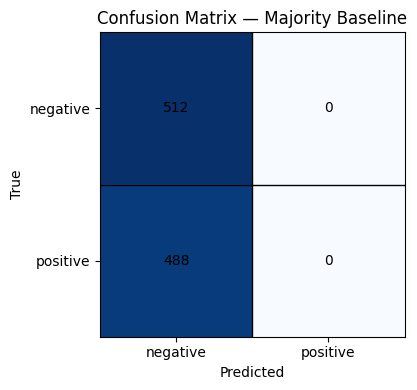

In [ ]:
# Visualize the confusion matrix for the majority baseline.

import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

def print_confusion_matrix(y_true, y_pred, labels=("negative", "positive"), title="Confusion Matrix"):
    '''
    Print a confusion matrix for the given true and predicted labels.
    '''
    cm = confusion_matrix(y_true, y_pred)

    fig, ax = plt.subplots(figsize=(5, 4))
    im = ax.imshow(cm, cmap="Blues")

    ax.set(
        xticks=[0, 1],
        yticks=[0, 1],
        xticklabels=labels,
        yticklabels=labels,
        xlabel="Predicted",
        ylabel="True",
        title=title,
    )

    # Black lines between the cells.
    ax.set_xticks([0.5], minor=True)
    ax.set_yticks([0.5], minor=True)
    ax.grid(which="minor", color="black", linestyle="-", linewidth=1)
    ax.tick_params(which="minor", bottom=False, left=False)

    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            ax.text(j, i, cm[i, j], ha="center", va="center", color="black")

    plt.tight_layout()
    plt.show()


print_confusion_matrix(
    y_test,
    maj_pred,
    title="Confusion Matrix — Majority Baseline",
)


### Vectorize + train

Documents become TF-IDF vectors (Session 2!) — then a linear classifier (Logistic Regression) learns which weighted words signal which label.

In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

vectorizer = TfidfVectorizer(stop_words="english", ngram_range=(1, 2), min_df=2)
Xtr = vectorizer.fit_transform(X_train)
Xte = vectorizer.transform(X_test)

clf = LogisticRegression(max_iter=1000)
clf.fit(Xtr, y_train)
print("trained on", Xtr.shape[0], "docs ·", Xtr.shape[1], "features")

trained on 4000 docs · 51927 features


accuracy 0.838 · F1 0.837
              precision    recall  f1-score   support

    negative       0.85      0.82      0.84       512
    positive       0.82      0.85      0.84       488

    accuracy                           0.84      1000
   macro avg       0.84      0.84      0.84      1000
weighted avg       0.84      0.84      0.84      1000



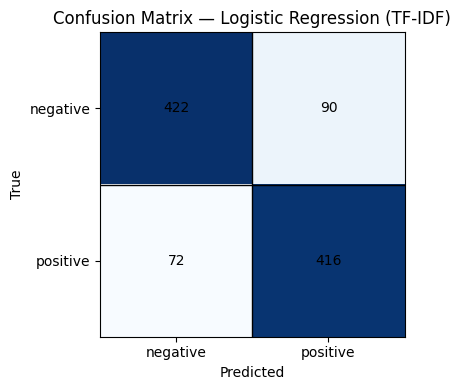

In [ ]:
# Evaluate on held-out data
from sklearn.metrics import accuracy_score, f1_score, classification_report

pred = clf.predict(Xte)
print(f"accuracy {accuracy_score(y_test, pred):.3f} · F1 {f1_score(y_test, pred):.3f}")
print(classification_report(y_test, pred, target_names=["negative", "positive"]))
print_confusion_matrix(
    y_test,
    pred,
    title="Confusion Matrix — Logistic Regression (TF-IDF)",
)

In [ ]:
# Which words drive the decision? Linear models are interpretable.
import numpy as np
terms = np.array(vectorizer.get_feature_names_out())
coefs = clf.coef_.ravel()
print("most POSITIVE:", ", ".join(terms[coefs.argsort()[::-1][:10]]))
print("most NEGATIVE:", ", ".join(terms[coefs.argsort()[:10]]))

most POSITIVE: great, best, love, excellent, wonderful, amazing, beautiful, perfect, fun, favorite
most NEGATIVE: bad, worst, waste, boring, awful, poor, just, terrible, plot, minutes


### Error Analysis: Inspect the misclassifications

In [ ]:
wrong = [i for i, (p, y) in enumerate(zip(pred, y_test)) if p != y]
print(len(wrong), "misclassified of", len(y_test))
for i in wrong[:3]:
    print(f"\n--- true={y_test[i]} pred={pred[i]} ---")
    print(X_test[i][:400])

162 misclassified of 1000

--- true=0 pred=1 ---
Not much to say other than plenty of Wire-fu and supposed Sholin monks ego-tripping about Kung-fu and caricature Japanese plotting to take over China. All of this would not be so bad if not for the utterly fake Japanese sword fighting. If you watched a Samurai movie or two you can tell that the "Japanese" fighting in the movie is simply the same "Kung-fu" (Really circus acrobats) stunt men doing t

--- true=1 pred=0 ---
It could be easy to complain about the quality of this movie (you don't have to throw cartloads of money at a movie to make it good, nor will it guarantee that it is worth watching) but I think that is totally missing the point. If your expecting fast cars, T&A or a movie that will spell itself out for you then don't watch this, you'll be disappointed and dumbfounded.<br /><br />This movie was tho

--- true=0 pred=1 ---
Intended as light entertainment, this film is indeed successful as such during its first half, but then

**👉 Your turn** — read a few misclassified reviews. Do you spot patterns? Negation, sarcasm, and mixed reviews are the classic failure modes. Look closely at negation: because `stop_words="english"` removes "not" *before* the bigrams are built, "not bad at all" collapses to "bad" — so even adding bigrams doesn't rescue it. (Try re-running the vectorizer with `stop_words=None` to see the difference.)

### Why not just add more n-grams? — the sparsity wall

Bigrams *do* catch some negation, but the feature space explodes and most of those columns are nearly empty and hard to learn from.

In [ ]:
# More n-grams = more columns, most appearing in only a doc or two
from sklearn.feature_extraction.text import TfidfVectorizer
for ng in [(1, 1), (1, 2), (1, 3)]:
    v = TfidfVectorizer(stop_words="english", ngram_range=ng, min_df=1)
    n_feats = v.fit_transform(X_train).shape[1]
    print(f"ngram_range={ng}: {n_feats:>9,} features")

# Dense transformer embeddings pack meaning into a few hundred dimensions instead —
# similar phrases share structure, so there is far less to learn from scratch.

ngram_range=(1, 1):    34,506 features
ngram_range=(1, 2):   369,708 features
ngram_range=(1, 3):   786,351 features


## 2 · Task 1: sentiment with transformers

### Sub-words: how transformers see text

No stemming, no stopword removal: transformers use **sub-word tokenization** via Byte-pair encoding (BPE), WordPiece, or Unigram. Rare words split into frequent pieces, so no word is ever out-of-vocabulary.

GPT-2 uses true BPE, DistilBERT, which you'll use next, uses WordPiece instead — same idea, different algorithm

**Important: Always use the tokenizer that was trained together with the model.**

In [ ]:
from transformers import AutoTokenizer

tok = AutoTokenizer.from_pretrained("gpt2")  # GPT-2 uses true byte-pair encoding (BPE)
for word in ["unbelievable", "Zurich", "tokenization", "antidisestablishmentarianism"]:
    pieces = tok.tokenize(word)
    print(f"{word:>32} → {pieces}")


config.json:   0%|          | 0.00/665 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.04M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

                    unbelievable → ['un', 'bel', 'iev', 'able']
                          Zurich → ['Z', 'ur', 'ich']
                    tokenization → ['token', 'ization']
    antidisestablishmentarianism → ['ant', 'idis', 'establishment', 'arian', 'ism']


### Contextual embeddings: one word, different vectors

The benefit of attention: the **same** word gets a **different** vector depending on its sentence — exactly what Session 2's static embeddings could not do.

In [ ]:
# Contextual embeddings: the same word can mean different things in different sentences.

import torch
from transformers import AutoTokenizer, AutoModel
from transformers import logging

# Silence warnings about missing LM head weights — we only need the base encoder.
logging.set_verbosity_error()

# Load tokenizer and model for a pretrained DistilBERT encoder.
emb_name = "distilbert-base-uncased"
ctx_tok = AutoTokenizer.from_pretrained(emb_name)
ctx_model = AutoModel.from_pretrained(emb_name)

def word_vector(sentence, word):
    # Tokenize the sentence and convert it to tensors for the model.
    enc = ctx_tok(sentence, return_tensors="pt")

    # No gradients needed: we are only doing inference, not training.
    with torch.no_grad():
        hidden = ctx_model(**enc).last_hidden_state[0]

    # Convert token IDs back to tokens so we can find the target word.
    toks = ctx_tok.convert_ids_to_tokens(enc["input_ids"][0])

    # Return the hidden-state vector for the chosen token.
    # Here we assume the word appears as a single token.
    return hidden[toks.index(word)]

# Get the representation of "bank" in two different contexts.
v1 = word_vector("i sat on the river bank", "bank")
v2 = word_vector("i opened a bank account", "bank")

# Compare the two vectors: lower similarity means different meanings.
cos = torch.nn.functional.cosine_similarity(v1, v2, dim=0).item()

print(f"\ncosine similarity of 'bank' across the two sentences: {cos:.2f}")
print("→ less than 1.0: the model represents the two 'bank's differently")

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/268M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]


cosine similarity of 'bank' across the two sentences: 0.60
→ less than 1.0: the model represents the two 'bank's differently


### Transformer sentiment pipeline on your test set

In [ ]:
import time
from transformers import pipeline

# Load a pretrained sentiment classifier.
# This model was fine-tuned on SST-2 and returns labels like POSITIVE / NEGATIVE.
sentiment = pipeline(
    "sentiment-analysis",
    model="distilbert-base-uncased-finetuned-sst-2-english",
    truncation=True,   # DistilBERT reads at most 512 tokens — longer reviews are cut off (measured below)
)

# Measure how long inference takes on the whole test set.
t0 = time.perf_counter()
# Run the model in batches for better speed.
tf_pred_raw = sentiment(list(X_test), batch_size=32)
tf_time = time.perf_counter() - t0

# Convert text labels returned by the pipeline into 0/1 labels
# so we can compare them with the sklearn baseline.
tf_pred = [1 if r["label"] == "POSITIVE" else 0 for r in tf_pred_raw]

print(f"transformer inference: {tf_time:.1f} s for {len(X_test)} docs")

config.json:   0%|          | 0.00/629 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/268M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

transformer inference: 958.7 s for 1000 docs


### Did truncation cost us anything?

`truncation=True` silently drops everything after token 512. Before trusting the scores, check how many test reviews were actually affected — a design choice should be measured, not assumed harmless.

(Preview of Session 4: LLM context windows are far larger — hundreds of thousands of tokens — so this particular constraint disappears, at a price.)

In [ ]:
# How many reviews did truncation affect?
# We reuse the pipeline's own tokenizer, so the counts match exactly what the model saw.
# (Token counts include the special [CLS]/[SEP] tokens, same as the 512 limit does.)

lengths = [len(sentiment.tokenizer(doc)["input_ids"]) for doc in X_test]
over = sum(1 for n in lengths if n > 512)

print(f"{over} of {len(X_test)} test reviews exceed 512 tokens ({over / len(X_test):.0%})")
print(f"length range: {min(lengths)}–{max(lengths)} tokens · mean {sum(lengths) / len(lengths):.0f}")

124 of 1000 test reviews exceed 512 tokens (12%)
length range: 35–1470 tokens · mean 289


In [ ]:
# Side-by-side comparison with the baseline

# Measure how long the sklearn baseline takes to make predictions.
import time
t0 = time.perf_counter()
_ = clf.predict(Xte)
sk_time = time.perf_counter() - t0

# Use the same metrics for both models so the comparison is fair.
from sklearn.metrics import accuracy_score, f1_score

# Print a compact table with accuracy, F1, and runtime.
print(f"{'':>14} {'accuracy':>9} {'F1':>7} {'time':>9}")
print(f"{'majority':>14} {accuracy_score(y_test, maj_pred):>9.3f} {f1_score(y_test, maj_pred, zero_division=0):>7.3f} {'—':>9}")
print(f"{'baseline':>14} {accuracy_score(y_test, pred):>9.3f} {f1_score(y_test, pred):>7.3f} {sk_time:>8.2f}s")
print(f"{'transformer':>14} {accuracy_score(y_test, tf_pred):>9.3f} {f1_score(y_test, tf_pred):>7.3f} {tf_time:>8.1f}s")

                accuracy      F1      time
      majority     0.512   0.000         —
      baseline     0.838   0.837     0.01s
   transformer     0.881   0.876    958.7s


In [ ]:
# Where do the two models disagree and who wins?

# Find the test examples where the baseline and transformer made different predictions.
disagree = [i for i in range(len(y_test)) if pred[i] != tf_pred[i]]

# Count how many disagreements there are in total.
print(len(disagree), "disagreements")

# Show a few disagreement examples so we can inspect them manually.
for i in disagree[:5]:
    print(f"\n--- true={y_test[i]} baseline={pred[i]} transformer={tf_pred[i]} ---")
    print(X_test[i][:300])

193 disagreements

--- true=1 baseline=1 transformer=0 ---
I was truly and wonderfully surprised at "O' Brother, Where Art Thou?" The video store was out of all the movies I was planning on renting, so then I came across this. I came home and as I watched I became engrossed and found myself laughing out loud. The Coen's have made a magnificiant film again. 

--- true=0 baseline=0 transformer=1 ---
A holiday on a boat, a married couple, an angry waiter and a shipwreck is the reason to this films beginning.<br /><br />I like boobs. No question about that. But when the main character allies with whoever happens to have the most fish at the moment, mostly by having sex with them and playing the r

--- true=0 baseline=1 transformer=0 ---
Not much to say other than plenty of Wire-fu and supposed Sholin monks ego-tripping about Kung-fu and caricature Japanese plotting to take over China. All of this would not be so bad if not for the utterly fake Japanese sword fighting. If you watched a Samu

**👉 Your turn** — write two tricky reviews yourself (use negation or sarcasm) and test both models on them.

The trade-off you just measured (accuracy vs. runtime vs. interpretability) refer exactly to question 3 and 4 on our list:
- Is the simplest tool good enough?
- What are the constraints?

In [ ]:
# your code here...

## 3 · Task 2: keyword extraction — TF-IDF baseline vs. KeyBERT

Same pattern as sentiment: **classical baseline first, then the transformer, on the same document.**

The classical way to get keywords is the top **TF-IDF terms** of a document (Session 2!): words frequent in *this* review but rare across the corpus. KeyBERT instead ranks candidate phrases by **embedding similarity** to the whole document. Both use `(1, 2)`-grams and English stopword removal here, so the comparison is fair.

**Note the output shape:** both produce a fixed list of phrases. (Next session we ask an LLM the same thing as a *question* — "what is this about?" — and watch the answer become free-form natural language.)

In [ ]:
# Classical baseline: the top TF-IDF terms of one document.
# We reuse the vectorizer from Section 1 — its IDF weights come from the training corpus,
# so "keyword" here means: frequent in THIS review, rare across reviews.

import numpy as np

# Pick one review to inspect (the same one goes to KeyBERT below).
sample_review = X_test[5]

# Turn the single review into its TF-IDF vector.
row = vectorizer.transform([sample_review]).toarray().ravel()
terms = vectorizer.get_feature_names_out()

# Take the 5 terms with the highest TF-IDF weight in this document.
top_idx = row.argsort()[::-1][:5]
tfidf_kw = [(terms[i], round(float(row[i]), 3)) for i in top_idx if row[i] > 0]

print(sample_review[:300], "...\n")
print("TF-IDF keywords:", tfidf_kw)

After a very long time Marathi cinema has come with some good movie.This movie is one of the best Marathi movies ever made. It shows how a old grandfather tries to save his grandsons eye. He tries everything that is possible in his hands to save the child's eye. Doctor and a relative of his tries to ...

TF-IDF keywords: [('grandfather', 0.299), ('tries', 0.266), ('doctor', 0.216), ('eye', 0.198), ('save', 0.19)]


In [ ]:
# KeyBERT: rank candidate phrases by embedding similarity to the whole document.

from keybert import KeyBERT

# Load the keyword extraction model.
kw_model = KeyBERT()

# Extract the top 5 keywords / keyphrases from the SAME review.
# keyphrase_ngram_range=(1, 2) allows single words and two-word phrases.
# stop_words="english" removes common filler words from candidate phrases.
keywords = kw_model.extract_keywords(
    sample_review,
    keyphrase_ngram_range=(1, 2),
    stop_words="english",
    top_n=5
)

print("KeyBERT keywords:", keywords)

ModuleNotFoundError: No module named 'keybert'

In [ ]:
# Side-by-side: same document, two definitions of "keyword".

from itertools import zip_longest

print(f"{'TF-IDF (corpus-distinctive)':<36}{'KeyBERT (semantically central)'}")
print("-" * 70)
for a, b in zip_longest(tfidf_kw, keywords, fillvalue=("—", 0.0)):
    print(f"{a[0]:<26}{a[1]:<10}{b[0]:<26}{b[1]:.2f}")

**👉 Your turn** — change `sample_review` to a different index and re-run all three cells. Where do the two lists agree, and where do they diverge? Two structural differences to notice:

- **TF-IDF needs a corpus** (the weights are corpus-relative) and can only return terms that survived `min_df=2` on the training set. **KeyBERT works on a single document** with no corpus at all.
- TF-IDF rewards *distinctive* terms (rare names often win); KeyBERT rewards phrases *semantically close to the document as a whole* — which is not the same thing.

## 4 · Task 3: named-entity recognition (NER)

The third dedicated-model task: a transformer **NER pipeline** that finds and labels entities (people, organizations, locations, dates, money). Like sentiment and keywords, it's a pretrained model you download and call (no training on your side).

Next session we redo NER by *prompting an LLM* and compare the approaches, so **keep the failure cases you find here.**

In [ ]:
# Load the NER pipeline.
# This pretrained model identifies named entities such as people, organizations, and locations.
from transformers import pipeline

# aggregation_strategy="simple" combines subword pieces into full entity spans.
ner = pipeline("ner", model="dslim/bert-base-NER", aggregation_strategy="simple")

# Example text to analyze.
article = (
    "Anna Keller, a researcher at the University of Zurich, presented her findings "
    "in Geneva on Tuesday. The study, funded by the Swiss National Science Foundation "
    "with 2.4 million francs, analyzed social media posts from Reddit and X. "
    "Keller previously worked at ETH and at Google in London."
)

# Run the model and return a list of detected entities.
entities = ner(article)

# Print each entity with its label, confidence score, and text span.
for e in entities:
    print(f"{e['entity_group']:>5}  {e['score']:.2f}  {e['word']}")

In [ ]:
# Group the extracted entities by label type.

from collections import defaultdict

# Create a list for each entity group (e.g. PER, ORG, LOC).
by_type = defaultdict(list)

# Add each detected word/span to its corresponding label.
for e in entities:
    by_type[e["entity_group"]].append(e["word"])

# Convert to a regular dict for display.
dict(by_type)

In [ ]:
# Visualize the spans with spaCy's displaCy.
# Manual mode lets us render the Hugging Face entity spans directly.
from spacy import displacy

# Convert the detected entities into the start/end/label format displaCy expects.
ents = [{"start": e["start"], "end": e["end"], "label": e["entity_group"]} for e in entities]

# Render the annotated text inline in the notebook.
displacy.render({"text": article, "ents": ents}, style="ent", manual=True, jupyter=True)

**👉 Your turn** — run the NER pipeline on a text from your own domain (or a news article). Collect the **failure cases**: unusual names, ambiguous spans, domain-specific entities it misses. Keep them — they become the test set for the LLM comparison in Session 4.

In [ ]:
my_text = """..."""   # paste your text here
failure_cases = []     # collect problematic examples — bring these to Session 4